
 MONTE CARLO UNCERTAINTY RESULTS
Input Tracking Noise Assumed: ±5.0 mm
Goal Width (Y):    3.299 ± 0.039 m
Goal Height (Z):   1.883 ± 0.040 m
95% Confidence Interval Y: [3.222, 3.375] m
95% Confidence Interval Z: [1.805, 1.961] m


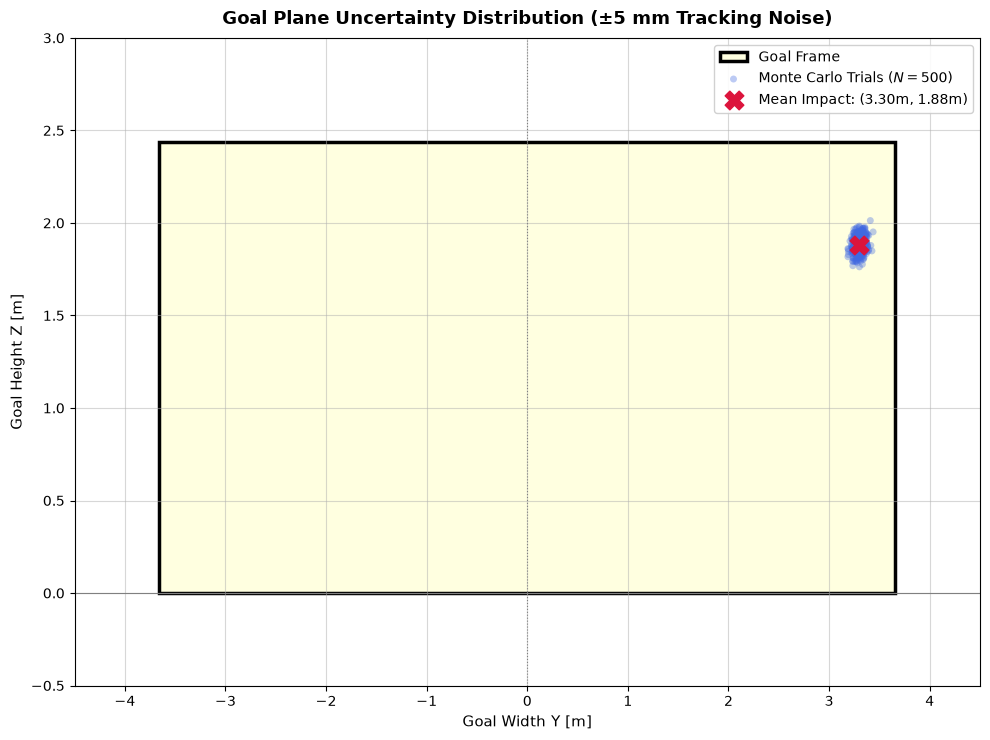

In [6]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp

# --- 1. Geometry & Simulation Setup ---
GOAL_X = 11.0
Y_MIN, Y_MAX = -3.66, 3.66
Z_MIN, Z_MAX = 0.0, 2.44
G = 9.81

# Base tracking coordinates
p0_base = np.array([0.00, 0.00, 0.11])  # t = 0.00 s
p1_base = np.array([1.50, 0.45, 0.44])  # t = 0.05 s
p2_base = np.array([2.96, 0.86, 0.74])  # t = 0.10 s
dt = 0.05
vz0_base = 6.94


# --- 2. ODE & Event Functions ---
def trajectory_ode(t, state, q, g):
    x, y, z, vx, vy, vz = state
    V = np.sqrt(vx**2 + vy**2 + vz**2)
    return [vx, vy, vz, -q * V * vx, -q * V * vy, -g - q * V * vz]


def goal_plane_event(t, state, q, g):
    return state[0] - GOAL_X


goal_plane_event.terminal = True
goal_plane_event.direction = 1


def simulate_impact(p0, p1, p2, vz0):
    vx1 = (p1[0] - p0[0]) / dt
    vx2 = (p2[0] - p1[0]) / dt

    L1 = np.linalg.norm(p1 - p0)
    L2 = np.linalg.norm(p2 - p1)
    ds = (L1 + L2) / 2.0

    # Drag parameter q
    q = np.log(vx1 / vx2) / ds

    # Initial velocities
    s1 = L1 / 2.0
    vx0 = vx1 * np.exp(q * s1)
    vy0 = vx0 * (p1[1] / p1[0])

    init_state = [p0[0], p0[1], p0[2], vx0, vy0, vz0]
    sol = solve_ivp(
        trajectory_ode,
        (0, 1.0),
        init_state,
        args=(q, G),
        events=goal_plane_event,
        max_step=0.001,
    )

    if len(sol.t_events[0]) > 0:
        return sol.t_events[0][0], sol.y_events[0][0][1], sol.y_events[0][0][2]
    return None, None, None


# --- 3. Monte Carlo Simulation ---
N_TRIALS = 500
NOISE_STD = 0.005  # ±5 mm Gaussian tracking noise
np.random.seed(42)

flight_times, y_impacts, z_impacts = [], [], []

for _ in range(N_TRIALS):
    p0_noisy = p0_base + np.random.normal(0, NOISE_STD, 3)
    p1_noisy = p1_base + np.random.normal(0, NOISE_STD, 3)
    p2_noisy = p2_base + np.random.normal(0, NOISE_STD, 3)

    t_g, y_g, z_g = simulate_impact(p0_noisy, p1_noisy, p2_noisy, vz0_base)
    if t_g is not None:
       
        flight_times.append(t_g)
        y_impacts.append(y_g)
        z_impacts.append(z_g)
        

y_mean, z_mean = np.mean(y_impacts), np.mean(z_impacts)

y_arr = np.array(y_impacts)
z_arr = np.array(z_impacts)



y_mean, y_std = np.mean(y_arr), np.std(y_arr)
z_mean, z_std = np.mean(z_arr), np.std(z_arr)


print("\n==========================================")
print(" MONTE CARLO UNCERTAINTY RESULTS")
print("==========================================")
print(f"Input Tracking Noise Assumed: ±{NOISE_STD*1000:.1f} mm")
print(f"Flight Time: {np.mean(flight_times):.4f} ± {np.std(flight_times, ddof=1):.4f} s")

print(f"Goal Width (Y):    {y_mean:.3f} ± {y_std:.3f} m")
print(f"Goal Height (Z):   {z_mean:.3f} ± {z_std:.3f} m")
print(f"95% Confidence Interval Y: [{y_mean - 1.96*y_std:.3f}, {y_mean + 1.96*y_std:.3f}] m")
print(f"95% Confidence Interval Z: [{z_mean - 1.96*z_std:.3f}, {z_mean + 1.96*z_std:.3f}] m")


# --- 4. Visualization ---
fig, ax = plt.subplots(figsize=(10, 7.5))

# Goal frame background fill and boundary outline
goal_bg = plt.Rectangle(
    (Y_MIN, Z_MIN),
    Y_MAX - Y_MIN,
    Z_MAX - Z_MIN,
    linewidth=2.5,
    edgecolor="black",
    facecolor="#FFFFE0",
    label="Goal Frame",
    zorder=1,
)
ax.add_patch(goal_bg)

# Reference grid guides
ax.axvline(0, color="gray", linestyle=":", linewidth=0.8, zorder=2)
ax.axhline(0, color="gray", linestyle="-", linewidth=0.8, zorder=2)

# Monte Carlo distribution scatter
ax.scatter(
    y_impacts,
    z_impacts,
    color="#4169E1",
    alpha=0.35,
    edgecolors="none",
    s=25,
    label=f"Monte Carlo Trials ($N = {N_TRIALS}$)",
    zorder=3,
)

# Mean Impact Point marker
ax.scatter(
    y_mean,
    z_mean,
    color="#DC143C",
    marker="X",
    s=180,
    zorder=4,
    label=f"Mean Impact: ({y_mean:.2f}m, {z_mean:.2f}m)",
)

# Plot constraints and labels
ax.set_xlim([-4.5, 4.5])
ax.set_ylim([-0.5, 3.0])
ax.set_xlabel("Goal Width Y [m]", fontsize=11)
ax.set_ylabel("Goal Height Z [m]", fontsize=11)
ax.set_title(
    "Goal Plane Uncertainty Distribution (±5 mm Tracking Noise)",
    fontsize=13,
    pad=10,
    fontweight="bold",
)
ax.grid(True, linestyle="-", alpha=0.5)
ax.legend(loc="upper right", framealpha=0.9, fontsize=10)

plt.tight_layout()
plt.show()